<a href="https://colab.research.google.com/github/Ghhaidaa/Data-Mining-Project-/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Performance and Study Habits — Phase 3 Final Report

This notebook brings together the project description, Decision Tree classification, and K-Means clustering. Sections 1–4 summarize earlier phases; their original code cells must also be incorporated from Phase1.ipynb and Phase2.ipynb before final submission.


# 1. Problem


Student academic performance is influenced by various factors, including study habits, attendance, sleep patterns, and previous academic achievement. Understanding how these factors relate to students' final grades is important for identifying academic performance patterns and supporting educational decision-making.

The main problem addressed in this project is the difficulty of understanding and predicting students' academic performance based on their study habits and other related characteristics.

This project aims to analyze student performance and study habits using data mining techniques to identify meaningful patterns, classify students according to their final grades, and discover groups of students with similar characteristics.

By analyzing these patterns, the project may provide useful insights into factors associated with academic performance and help identify students who may benefit from additional academic support.

# 2. Data Mining Task


## 2.1 Classification
Classification is a supervised data mining task used to predict predefined class labels based on input features.

In this project, Decision Tree was applied to classify students according to their final grades (A, B, C, D, and F). Two attribute selection measures were used: Gini Index and Information Gain (Entropy).

The dataset was divided into training and testing sets using three different partitions (90/10, 80/20, and 70/30) to evaluate the classification performance.

# 2.2 Clustering

Clustering is an unsupervised data mining task used to group similar data objects based on their characteristics without using predefined class labels.

In this project, K-Means was applied to group students based on their study habits and academic characteristics. Three different values of K (3, 4, and 5) were tested to identify meaningful student groups.

The clustering results were evaluated using Silhouette Score and the Elbow Method (WCSS) to determine the most suitable number of clusters.

# 3. Data

### 3.1 Dataset Description

The dataset used in this project is titled "Student Performance and Study Habits." It contains information about students' academic performance and study-related characteristics.

The dataset was obtained from Kaggle and contains 1,000 student records and 13 attributes.

### 3.2 Dataset Source

Source: Kaggle

Dataset: Student Performance and Study Habits

### 3.3 Dataset Attributes

The dataset contains 13 attributes, including:

- student_id
- gender
- study_time_hours
- attendance_percent
- sleep_hours
- parental_education
- internet_access
- extracurricular_activities
- part_time_job
- previous_grade
- final_exam_score
- final_grade
- study_time_category

These attributes describe students' demographic information, study habits, academic background, and final academic performance.
The preprocessed dataset contains 13 attributes. The `study_time_category` attribute was derived from the original `study_time_hours` attribute during the preprocessing phase.

### 3.4 Class Attribute

The target class attribute used for classification is `final_grade`, which contains five categories: A, B, C, D, and F.

These categories represent students' final academic performance and are used as predefined class labels in the Decision Tree classification task.

### 3.5 Dataset Inspection

We load the preprocessed dataset and inspect its dimensions, column names, data types, missing values, and target-class distribution before modeling. This provides a reproducible check of the data used in Phase 3.


In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [2]:
#Loading Data

df = pd.read_csv(
    "https://raw.githubusercontent.com/Ghhaidaa/Data-Mining-Project-/main/Dataset/Preprocessed_dataset.csv"
)

print(df.head())

   student_id  gender  study_time_hours  attendance_percent  sleep_hours  \
0           1    Male          0.460526            0.955752     0.485294   
1           2  Female          0.763158            1.000000     0.367647   
2           3    Male          0.578947            0.674779     0.691176   
3           4    Male          0.276316            0.502212     0.705882   
4           5    Male          0.223684            0.769912     0.205882   

  parental_education internet_access extracurricular_activities part_time_job  \
0          Bachelors             Yes                        Yes            No   
1        High School             Yes                        Yes           Yes   
2          Bachelors             Yes                         No           Yes   
3        High School             Yes                        Yes            No   
4          Bachelors             Yes                         No           Yes   

   previous_grade  final_exam_score final_grade study_ti

In [3]:
print('Dataset shape:', df.shape)
print(df.dtypes)
print('Missing values:', df.isna().sum().sum())
print('Class distribution:')
print(df['final_grade'].value_counts().sort_index())
print(df.head())


Dataset shape: (1000, 13)
student_id                      int64
gender                         object
study_time_hours              float64
attendance_percent            float64
sleep_hours                   float64
parental_education             object
internet_access                object
extracurricular_activities     object
part_time_job                  object
previous_grade                float64
final_exam_score              float64
final_grade                    object
study_time_category            object
dtype: object
Missing values: 0
Class distribution:
final_grade
A    284
B    354
C    261
D     89
F     12
Name: count, dtype: int64
   student_id  gender  study_time_hours  attendance_percent  sleep_hours  \
0           1    Male          0.460526            0.955752     0.485294   
1           2  Female          0.763158            1.000000     0.367647   
2           3    Male          0.578947            0.674779     0.691176   
3           4    Male          0.276316  

#  4. Data Preprocessing

### 4.1 Creating a Working Copy

Before applying preprocessing techniques, a separate working copy of the original dataset was created using `df_raw.copy()`. This ensured that the original dataset remained unchanged throughout the preprocessing process.

### 4.2 Missing Value Handling

The initial data analysis identified 102 missing values in the `parental_education` attribute, representing 10.2% of the dataset.

Since `parental_education` is a categorical attribute, the missing values were replaced using the most frequent value (Mode), which was High School.

After applying this technique, all 102 missing values were successfully handled, reducing the number of missing values in this attribute to zero while retaining all 1,000 student records.

### 4.3 Min-Max Normalization

Min-Max Normalization was applied to five numerical attributes:

- study_time_hours
- attendance_percent
- sleep_hours
- previous_grade
- final_exam_score

This technique transforms numerical values into a common range between 0 and 1.

Normalization was necessary because the numerical attributes originally had different value ranges. It also helps prevent attributes with larger numerical values from dominating distance-based techniques such as K-Means clustering.

After normalization, the minimum value of each selected attribute became 0, and the maximum value became 1.

### 4.4 Discretization

Discretization was applied to the `study_time_hours` attribute to convert continuous numerical values into three meaningful categories:

- Low: 3 hours or less.
- Medium: More than 3 and up to 5 hours.
- High: More than 5 hours.

The original study-time values were used to create these categories before normalization.

The resulting distribution was:

- Low: 366 students.
- Medium: 468 students.
- High: 166 students.

This technique makes study-time patterns easier to interpret and compare across different student groups.

### 4.5 Preprocessing Results

Three preprocessing techniques were successfully applied to prepare the dataset for the data mining tasks.

1. Missing Value Imputation: The 102 missing values in `parental_education` were replaced with the most frequent value (High School).

2. Min-Max Normalization: Five numerical attributes were scaled to a range between 0 and 1.

3. Discretization: The `study_time_hours` attribute was converted into Low, Medium, and High categories.

After preprocessing, the final dataset contained 1,000 records and 13 attributes, with no missing values remaining.

The preprocessed dataset was saved separately as `Preprocessed_dataset.csv`, while the original raw dataset remained unchanged.

**Phase 1–2 integration required before submission:** The descriptions above summarize preprocessing, but the original Phase 1 and Phase 2 code cells, raw-data snapshots, analysis plots, and preprocessing outputs must be inserted in their appropriate sections. The current Phase 3 file alone does not demonstrate those earlier operations. Do not treat this note as a substitute for those cells.


# 5. Data Mining Technique

## 5.1 Classification – Decision Tree


### Feature Selection

In this step, we selected the input features (X) and the target variable (y) for the Decision Tree classification.

The target variable is `final_grade`, which represents the student's final grade category.

We excluded `student_id` because it is only an identifier. We also excluded `final_exam_score` to avoid potential target leakage, since the final grade may be directly related to the exam score.

The remaining attributes were selected as input features to predict students' final grades.



In [4]:
#Feature Selection

X = df.drop(columns=['student_id', 'final_grade', 'final_exam_score'])
y = df['final_grade']

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['gender', 'study_time_hours', 'attendance_percent', 'sleep_hours', 'parental_education', 'internet_access', 'extracurricular_activities', 'part_time_job', 'previous_grade', 'study_time_category']
Target: final_grade


### Encoding Categorical Features

Before training the Decision Tree model, we converted the categorical input features into numerical values using `pd.get_dummies()`.

This step was necessary because the Decision Tree classifier in Scikit-learn requires numerical input features.

The `dtype=int` parameter was used to represent the encoded categories as 0 and 1. We then displayed the shape and first five rows of the transformed dataset to verify the result.

The target variable, `final_grade`, was kept unchanged because it represents the class labels we want to predict.


In [5]:
#Encoding Categorical Features

X = pd.get_dummies(X, dtype=int)

print("Features shape:", X.shape)
print(X.head())

Features shape: (1000, 19)
   study_time_hours  attendance_percent  sleep_hours  previous_grade  \
0          0.460526            0.955752     0.485294        0.663755   
1          0.763158            1.000000     0.367647        0.643377   
2          0.578947            0.674779     0.691176        0.832606   
3          0.276316            0.502212     0.705882        0.783115   
4          0.223684            0.769912     0.205882        0.443959   

   gender_Female  gender_Male  parental_education_Bachelors  \
0              0            1                             1   
1              1            0                             0   
2              0            1                             1   
3              0            1                             0   
4              0            1                             1   

   parental_education_High School  parental_education_Masters  \
0                               0                           0   
1                              

### Splitting Data

In this step, we used `train_test_split()` to divide the dataset into training and testing sets.

We applied three different partitions: **90% training / 10% testing**, **80% training / 20% testing**, and **70% training / 30% testing**, as required in Phase 3.

The training set is used to build the Decision Tree model, while the testing set is used to evaluate its accuracy on unseen data.

We used `random_state=42` to make the results reproducible. Each partition was stored in the `splits` dictionary so it could be used later to train and test the Gini and Entropy models.

Using these three partitions allows us to compare the classification results with different amounts of training and testing data.


In [6]:
#Splitting Data

splits = {}

for test_size in [0.10, 0.20, 0.30]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42
    )

    splits[test_size] = (X_train, X_test, y_train, y_test)

    print("Training:", int((1 - test_size) * 100), "%")
    print("Testing:", int(test_size * 100), "%")
    print("Training samples:", len(X_train))
    print("Testing samples:", len(X_test))
    print("--------------------")

Training: 90 %
Testing: 10 %
Training samples: 900
Testing samples: 100
--------------------
Training: 80 %
Testing: 20 %
Training samples: 800
Testing samples: 200
--------------------
Training: 70 %
Testing: 30 %
Training samples: 700
Testing samples: 300
--------------------


### Decision Tree Using Gini Index

In this step, we built Decision Tree classification models using the **Gini Index** as the splitting criterion.

We used `DecisionTreeClassifier(criterion='gini')` to create the models and applied them to the three training/testing partitions: 90/10, 80/20, and 70/30.

For each partition, the `fit()` method trained the model using the training data, while `predict()` generated predictions for the testing data.

The trained models were stored in the `gini_models` dictionary so they could be used later for evaluation and visualization.

The Gini Index measures the impurity of the data and helps the Decision Tree select suitable splits.

The accuracy and confusion matrices will be calculated in the evaluation section to assess the performance of each model.


In [7]:
#Decision Tree Using Gini Index

gini_models = {}

for test_size in [0.10, 0.20, 0.30]:

    X_train, X_test, y_train, y_test = splits[test_size]

    clf = DecisionTreeClassifier(criterion='gini', random_state=42)

    clf.fit(X_train, y_train)

    gini_models[test_size] = clf

    y_pred = clf.predict(X_test)

    print("Gini - Training:", int((1 - test_size) * 100), "%")
    print("Testing:", int(test_size * 100), "%")
    print("Model trained successfully")
    print("--------------------")

Gini - Training: 90 %
Testing: 10 %
Model trained successfully
--------------------
Gini - Training: 80 %
Testing: 20 %
Model trained successfully
--------------------
Gini - Training: 70 %
Testing: 30 %
Model trained successfully
--------------------


### Decision Tree Using Entropy (Information Gain)

In this step, we built three Decision Tree classification models using **Entropy (Information Gain)** as the splitting criterion.

We used `DecisionTreeClassifier(criterion='entropy')` and applied it to the same training/testing partitions used for Gini: 90/10, 80/20, and 70/30.

For each partition, the `fit()` method was used to train the model, while `predict()` was used to predict students' final grades.

The trained models were stored in the `entropy_models` dictionary for later evaluation and visualization.

Entropy measures the uncertainty in the class distribution, while Information Gain helps the Decision Tree select splits that reduce this uncertainty.

Using the same partitions for both Gini and Entropy allows us to compare their classification performance under consistent conditions.


In [8]:
#Decision Tree Using Entropy (Information Gain)

entropy_models = {}

for test_size in [0.10, 0.20, 0.30]:

    X_train, X_test, y_train, y_test = splits[test_size]

    clf = DecisionTreeClassifier(criterion='entropy', random_state=42)

    clf.fit(X_train, y_train)

    entropy_models[test_size] = clf

    y_pred = clf.predict(X_test)

    print("Entropy - Training:", int((1 - test_size) * 100), "%")
    print("Testing:", int(test_size * 100), "%")
    print("Model trained successfully")
    print("--------------------")

Entropy - Training: 90 %
Testing: 10 %
Model trained successfully
--------------------
Entropy - Training: 80 %
Testing: 20 %
Model trained successfully
--------------------
Entropy - Training: 70 %
Testing: 30 %
Model trained successfully
--------------------


## 5.2 Clustering — K-Means Implementation

K-Means groups students using five normalized numerical features. The same feature matrix is used for each K to make the comparisons consistent. We test K = 3, 4, and 5, calculate WCSS (inertia) and average Silhouette Score, and retain the cluster assignments for subsequent visualizations.


In [9]:
print(df.shape)
for column in df.columns:
    print(column)

(1000, 13)
student_id
gender
study_time_hours
attendance_percent
sleep_hours
parental_education
internet_access
extracurricular_activities
part_time_job
previous_grade
final_exam_score
final_grade
study_time_category


The dataset contains 1,000 student records and 13 columns. The available columns were examined to understand the dataset structure and identify the relevant features for the clustering process.

In [10]:
features = ['study_time_hours', 'attendance_percent', 'sleep_hours', 'previous_grade', 'final_exam_score']
X_cluster = df[features].copy()
print(X_cluster.head())


   study_time_hours  attendance_percent  sleep_hours  previous_grade  \
0          0.460526            0.955752     0.485294        0.663755   
1          0.763158            1.000000     0.367647        0.643377   
2          0.578947            0.674779     0.691176        0.832606   
3          0.276316            0.502212     0.705882        0.783115   
4          0.223684            0.769912     0.205882        0.443959   

   final_exam_score  
0          1.000000  
1          1.000000  
2          0.949248  
3          0.695489  
4          0.404135  


Five normalized numerical attributes were selected for K-Means: study time, attendance percentage, sleep hours, previous grade, and final exam score. `student_id` was excluded because it is an identifier. The selected data are stored in `X_cluster`, separately from the classification features, to prevent accidental overwriting.


In [11]:
cluster_metrics = {}
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
kmeans = KMeans(n_clusters=5, random_state=42)

labels = kmeans.fit_predict(X_cluster)

wcss = kmeans.inertia_
silhouette = silhouette_score(X_cluster, labels)

print("K = 5")
print("WCSS:", wcss)
print("Silhouette Score:", silhouette)
cluster_metrics[5] = {"WCSS": wcss, "Silhouette Score": silhouette}


K = 5
WCSS: 100.52948509528173
Silhouette Score: 0.15481344254978177


In this experiment, K-Means was applied using five clusters. The algorithm assigned each student to one of the five clusters based on the selected numerical features. WCSS and Silhouette Score were calculated to evaluate the clustering results.

In [12]:
kmeans = KMeans(n_clusters=4, random_state=42)

labels = kmeans.fit_predict(X_cluster)

wcss = kmeans.inertia_
silhouette = silhouette_score(X_cluster, labels)

print("K = 4")
print("WCSS:", wcss)
print("Silhouette Score:", silhouette)
cluster_metrics[4] = {"WCSS": wcss, "Silhouette Score": silhouette}


K = 4
WCSS: 109.30783720628511
Silhouette Score: 0.16011117688633483


In this experiment, K-Means was applied using four clusters with the same selected features. WCSS and Silhouette Score were calculated to measure cluster compactness and separation. The results were compared with the other K values.

In [13]:
kmeans = KMeans(n_clusters=3, random_state=42)

labels = kmeans.fit_predict(X_cluster)

wcss = kmeans.inertia_
silhouette = silhouette_score(X_cluster, labels)

print("K = 3")
print("WCSS:", wcss)
print("Silhouette Score:", silhouette)
cluster_metrics[3] = {"WCSS": wcss, "Silhouette Score": silhouette}


K = 3
WCSS: 121.28032281973174
Silhouette Score: 0.17708108327996802


In this experiment, K-Means was applied using three clusters. The same numerical features were used to ensure a fair comparison between the experiments. WCSS and Silhouette Score were calculated to evaluate the clustering quality.

# 6. Evaluation and Comparison

## 6.1 Classification – Evaluation

### Accuracy Evaluation

In this step, we evaluated the performance of the Decision Tree models using `metrics.accuracy_score()`, as demonstrated in the classification lab.

For each model, we used `predict()` to predict students' final grades from the testing data. We then compared the predicted grades with the actual grades to calculate the classification accuracy.

We evaluated both Gini and Entropy using three training/testing partitions: 90/10, 80/20, and 70/30, resulting in six accuracy values.

Accuracy represents the percentage of students whose final grades were predicted correctly. These results will be used to compare the performance of the two splitting criteria.


In [14]:
#Accuracy Evaluation

for criterion, models in [('Gini', gini_models),
                          ('Entropy', entropy_models)]:

    for test_size in [0.10, 0.20, 0.30]:

        X_train, X_test, y_train, y_test = splits[test_size]

        clf = models[test_size]

        y_pred = clf.predict(X_test)

        accuracy = metrics.accuracy_score(y_test, y_pred)

        print("Criterion:", criterion)
        print("Training:", int((1 - test_size) * 100), "%")
        print("Testing:", int(test_size * 100), "%")
        print("Accuracy:", round(accuracy * 100, 2), "%")
        print("--------------------")

Criterion: Gini
Training: 90 %
Testing: 10 %
Accuracy: 42.0 %
--------------------
Criterion: Gini
Training: 80 %
Testing: 20 %
Accuracy: 43.5 %
--------------------
Criterion: Gini
Training: 70 %
Testing: 30 %
Accuracy: 45.67 %
--------------------
Criterion: Entropy
Training: 90 %
Testing: 10 %
Accuracy: 44.0 %
--------------------
Criterion: Entropy
Training: 80 %
Testing: 20 %
Accuracy: 42.5 %
--------------------
Criterion: Entropy
Training: 70 %
Testing: 30 %
Accuracy: 43.0 %
--------------------


### Accuracy Comparison Table

The table summarizes the classification accuracy of the Decision Tree models using Gini Index and Entropy across the three training/testing partitions.

We calculated the accuracy using `metrics.accuracy_score()` and organized the results into a table using Pandas.

For the 90/10 partition, Entropy achieved higher accuracy (44%) than Gini (42%). However, Gini performed better in the 80/20 and 70/30 partitions.

The highest accuracy was **45.67%**, achieved by Gini using the 70/30 partition.

This table provides a clear comparison of the six experiments and shows how the accuracy varied across the two splitting criteria and three partitions.


In [15]:
# Accuracy Comparison Table

results = []

for criterion, models in [('Gini', gini_models),
                          ('Entropy', entropy_models)]:

    row = {'Criterion': criterion}

    for test_size in [0.10, 0.20, 0.30]:

        X_train, X_test, y_train, y_test = splits[test_size]

        clf = models[test_size]
        y_pred = clf.predict(X_test)

        accuracy = metrics.accuracy_score(y_test, y_pred)

        partition = f"{int((1-test_size)*100)}/{int(test_size*100)}"
        row[partition] = round(accuracy * 100, 2)

    results.append(row)

comparison_table = pd.DataFrame(results)
print(comparison_table)

  Criterion  90/10  80/20  70/30
0      Gini   42.0   43.5  45.67
1   Entropy   44.0   42.5  43.00


### Confusion Matrix Evaluation

In this step, we used `confusion_matrix()` and `ConfusionMatrixDisplay` to evaluate and visualize the predictions of the six Decision Tree models.

Each confusion matrix compares the actual student grades with the predicted grades. The rows represent the actual grades, while the columns represent the predicted grades. Values on the main diagonal indicate correct predictions, whereas values outside the diagonal indicate incorrect predictions.

**Gini Index Results:**

* **90/10:** The model correctly classified 42 out of 100 students. Grade B had the highest number of correct predictions (20), while grade F had no correct predictions.
* **80/20:** The model correctly classified 87 out of 200 students. Grades A and B each had 30 correct predictions, while grade F had none.
* **70/30:** The model correctly classified 137 out of 300 students. Grade B had the highest number of correct predictions (51), followed by grade A (45) and grade C (35).

**Entropy Results:**

* **90/10:** The model correctly classified 44 out of 100 students. Grades B and C each had 15 correct predictions, while grades D and F had none.
* **80/20:** The model correctly classified 85 out of 200 students. Grade B had the highest number of correct predictions (35), followed by grade A (24).
* **70/30:** The model correctly classified 129 out of 300 students. Grade B had the highest number of correct predictions (48), followed by grade A (45) and grade C (34).

**Overall Observation:**

The confusion matrices show that both Gini and Entropy correctly classified some students in grades A, B, and C, but experienced difficulty classifying grades D and F.

A common classification error was confusing grades B and C. For example, in the 70/30 partition, Gini classified 28 students with an actual grade of C as B, while Entropy classified 33 students with an actual grade of C as B.

These results show that the models had difficulty distinguishing between certain grade categories, which is consistent with the relatively low accuracy values.


Criterion: Gini
Training: 90 %
Testing: 10 %
Confusion Matrix:
[[11  9  0  0  0]
 [ 8 20 10  1  0]
 [ 4  9 10  4  0]
 [ 0  7  4  1  1]
 [ 0  1  0  0  0]]


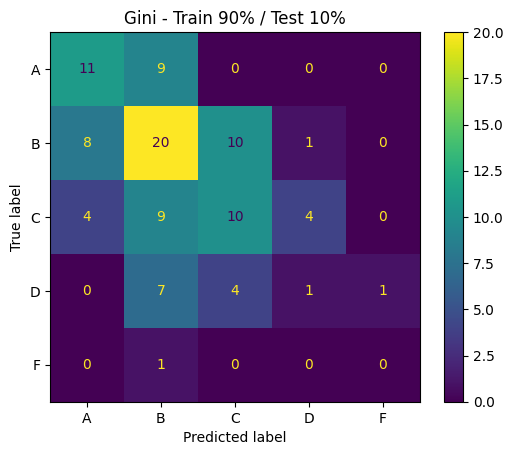

Criterion: Gini
Training: 80 %
Testing: 20 %
Confusion Matrix:
[[30 14  2  1  0]
 [19 30 15  9  0]
 [ 3 21 22  8  1]
 [ 0 11  6  5  1]
 [ 0  1  1  0  0]]


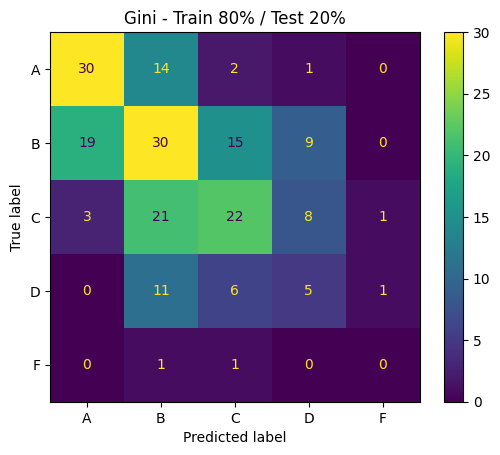

Criterion: Gini
Training: 70 %
Testing: 30 %
Confusion Matrix:
[[45 25  6  0  1]
 [31 51 17  5  0]
 [11 28 35  8  1]
 [ 1 10 16  6  1]
 [ 0  0  2  0  0]]


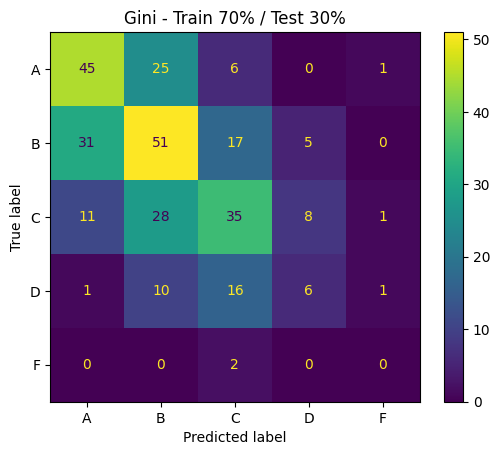

Criterion: Entropy
Training: 90 %
Testing: 10 %
Confusion Matrix:
[[14  6  0  0  0]
 [13 15 10  1  0]
 [ 1  7 15  3  1]
 [ 1  6  5  0  1]
 [ 0  1  0  0  0]]


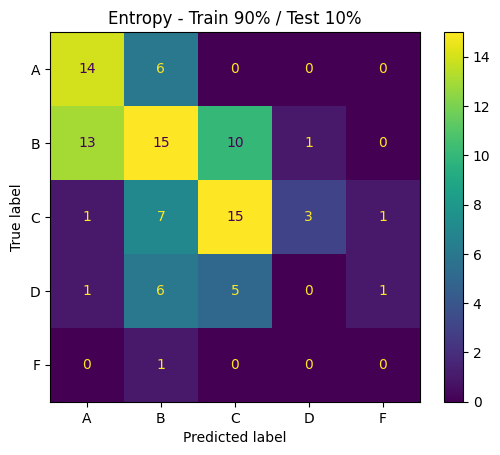

Criterion: Entropy
Training: 80 %
Testing: 20 %
Confusion Matrix:
[[24 17  4  2  0]
 [14 35 20  3  1]
 [ 4 19 22  9  1]
 [ 5  7  7  4  0]
 [ 0  1  0  1  0]]


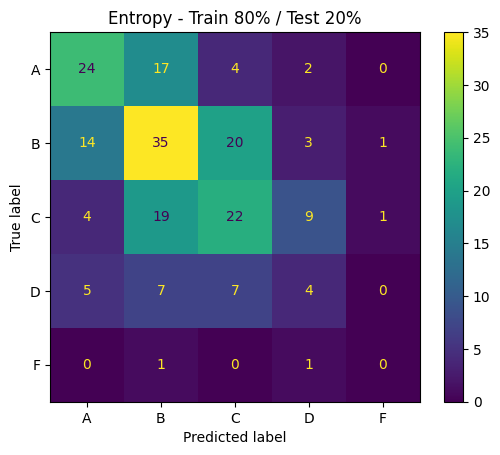

Criterion: Entropy
Training: 70 %
Testing: 30 %
Confusion Matrix:
[[45 25  6  1  0]
 [28 48 25  3  0]
 [ 7 33 34  7  2]
 [ 2 11 18  2  1]
 [ 0  0  1  1  0]]


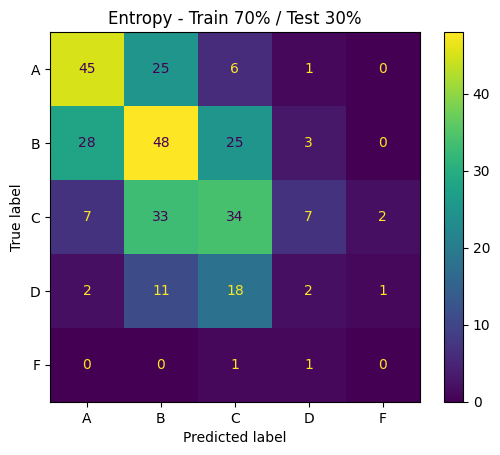

In [16]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for criterion, models in [('Gini', gini_models),
                          ('Entropy', entropy_models)]:

    for test_size in [0.10, 0.20, 0.30]:

        X_train, X_test, y_train, y_test = splits[test_size]

        clf = models[test_size]
        y_pred = clf.predict(X_test)

        cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)

        print("Criterion:", criterion)
        print("Training:", int((1 - test_size) * 100), "%")
        print("Testing:", int(test_size * 100), "%")
        print("Confusion Matrix:")
        print(cm)

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=clf.classes_
        )

        disp.plot()
        plt.title(
            f"{criterion} - Train {int((1-test_size)*100)}% / "
            f"Test {int(test_size*100)}%"
        )
        plt.show()

### Accuracy Results

The Decision Tree models were evaluated using three training/testing partitions and two splitting criteria: Gini Index and Entropy.

**Gini Index Results:**

* **90/10:** The model achieved 42% accuracy, correctly predicting 42 out of 100 students.
* **80/20:** The model achieved 43.5% accuracy, correctly predicting 87 out of 200 students.
* **70/30:** The model achieved 45.67% accuracy, correctly predicting 137 out of 300 students.

**Entropy Results:**

* **90/10:** The model achieved 44% accuracy, correctly predicting 44 out of 100 students.
* **80/20:** The model achieved 42.5% accuracy, correctly predicting 85 out of 200 students.
* **70/30:** The model achieved 43% accuracy, correctly predicting 129 out of 300 students.

**Results Comparison:**

For the 90/10 partition, Entropy achieved higher accuracy than Gini by 2 percentage points.

For the 80/20 partition, Gini achieved higher accuracy than Entropy by 1 percentage point.

For the 70/30 partition, Gini achieved higher accuracy than Entropy by approximately 2.67 percentage points.

The highest accuracy was **45.67%**, achieved using Gini Index with the 70/30 partition.

However, all six models achieved accuracy below 50%, indicating that the models made more incorrect predictions than correct predictions on their respective testing sets.

These results show that both the splitting criterion and the training/testing partition affected the observed classification accuracy.


### Best Classification Model by Partition

We compare Gini and Entropy on the same test subset within each partition, then identify the highest testing accuracy across all six trained models. The chosen model is the best **among the evaluated experiments**, not necessarily the best possible classifier.


In [17]:
classification_results = []
for test_size in [0.10, 0.20, 0.30]:
    _, X_test, _, y_test = splits[test_size]
    for criterion, models in [('Gini', gini_models), ('Entropy', entropy_models)]:
        accuracy = metrics.accuracy_score(y_test, models[test_size].predict(X_test))
        classification_results.append({'Partition': f'{int((1-test_size)*100)}/{int(test_size*100)}', 'Test Size': test_size, 'Criterion': criterion, 'Accuracy': accuracy})
classification_table = pd.DataFrame(classification_results)
print(classification_table.pivot(index='Partition', columns='Criterion', values='Accuracy').round(4))
best_row = classification_table.loc[classification_table['Accuracy'].idxmax()]
best_model = (gini_models if best_row['Criterion'] == 'Gini' else entropy_models)[best_row['Test Size']]
print(f"Best tested model: {best_row['Criterion']}, {best_row['Partition']}, accuracy = {best_row['Accuracy']:.2%}")


Criterion  Entropy    Gini
Partition                 
70/30        0.430  0.4567
80/20        0.425  0.4350
90/10        0.440  0.4200
Best tested model: Gini, 70/30, accuracy = 45.67%


## 6.2 Clustering — Evaluation and Comparison

We compare K-Means models using WCSS (lower indicates more compact clusters for a fixed dataset) and Silhouette Score (higher indicates better relative cohesion and separation). Because WCSS generally decreases as K increases, it should not be used alone to select the largest K.


### Comparison of K-Means Results

In [18]:
comparison = pd.DataFrame([{'K': k, **cluster_metrics[k]} for k in sorted(cluster_metrics)])
print(comparison.round(6))


   K        WCSS  Silhouette Score
0  3  121.280323          0.177081
1  4  109.307837          0.160111
2  5  100.529485          0.154813


The results show that WCSS decreases as the number of clusters increases.

K = 5 achieved the lowest WCSS value (100.5295), indicating more compact clusters.

However, K = 3 achieved the highest Silhouette Score (0.1771), suggesting better cluster separation among the tested values.

The Silhouette Scores are relatively low, indicating that some overlap may exist between the clusters.

The Elbow Method and Silhouette Score help compare the results and choose the best number of clusters (K).

### Elbow Method


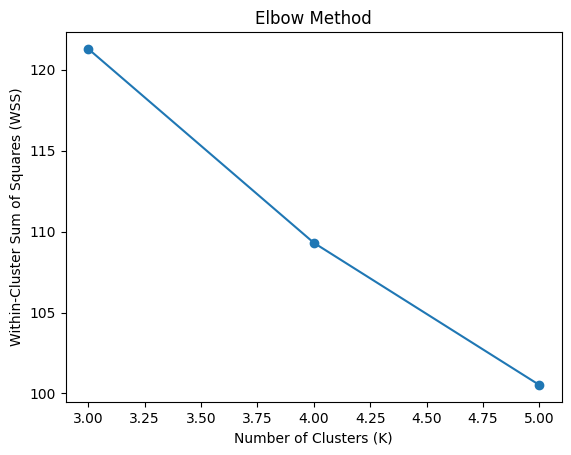

In [19]:
import matplotlib.pyplot as plt

k_values = [3, 4, 5]


wss_values = comparison['WCSS']

plt.plot(comparison['K'], wss_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WSS)')
plt.title('Elbow Method')
plt.show()


**Elbow Plot Description**

The WCSS decreases as the number of clusters increases. The plot shows a possible bend around K = 4, but no clearly defined elbow is observed. Therefore, the Elbow Method alone does not provide a conclusive choice of K.

### Silhouette Score Comparison

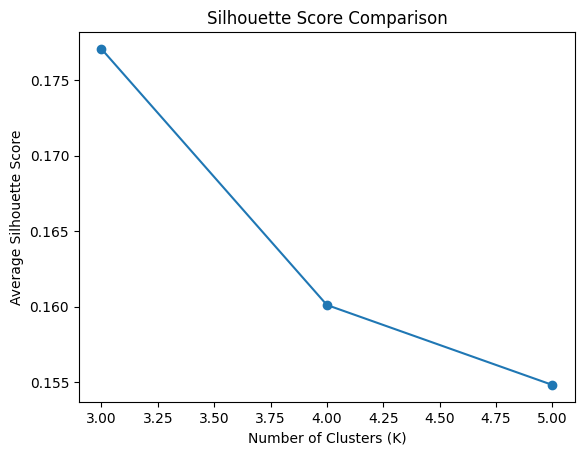

In [20]:
plt.plot(comparison['K'], comparison['Silhouette Score'], marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.show()

**Silhouette Score Plot Description**

The plot compares the Silhouette Scores for K = 3, K = 4, and K = 5. K = 3 achieved the highest score (0.1771), followed by K = 4 (0.1601) and K = 5 (0.1548). This indicates that K = 3 provides the best relative cluster separation among the tested values.

### Cluster Visualization and Interpretation

In [21]:
# Store cluster labels for each tested K
cluster_results = {}
for k in [3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=42)
    cluster_results[k] = model.fit_predict(X_cluster)
    print(f'K = {k}: {len(set(cluster_results[k]))} clusters')


K = 3: 3 clusters
K = 4: 4 clusters
K = 5: 5 clusters


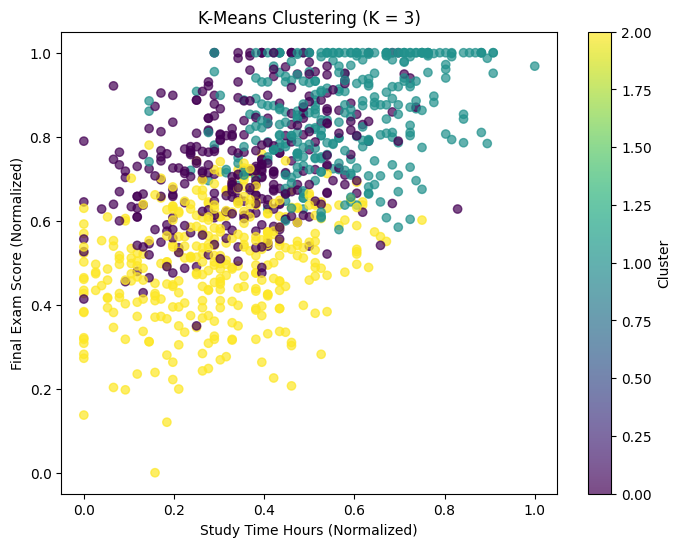

In [22]:

# Visualize clusters for K = 3
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['study_time_hours'],
    X_cluster['final_exam_score'],
    c=cluster_results[3],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('Study Time Hours (Normalized)')
plt.ylabel('Final Exam Score (Normalized)')
plt.title('K-Means Clustering (K = 3)')
plt.colorbar(label='Cluster')
plt.show()


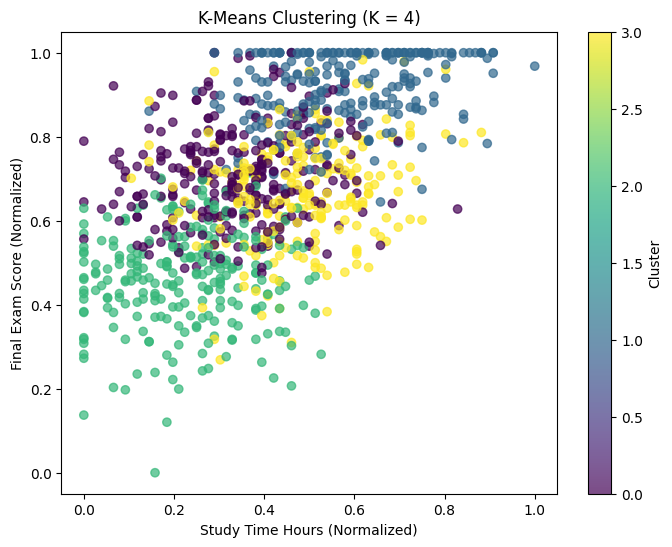

In [23]:

# Visualize clusters for K = 4
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['study_time_hours'],
    X_cluster['final_exam_score'],
    c=cluster_results[4],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('Study Time Hours (Normalized)')
plt.ylabel('Final Exam Score (Normalized)')
plt.title('K-Means Clustering (K = 4)')
plt.colorbar(label='Cluster')
plt.show()


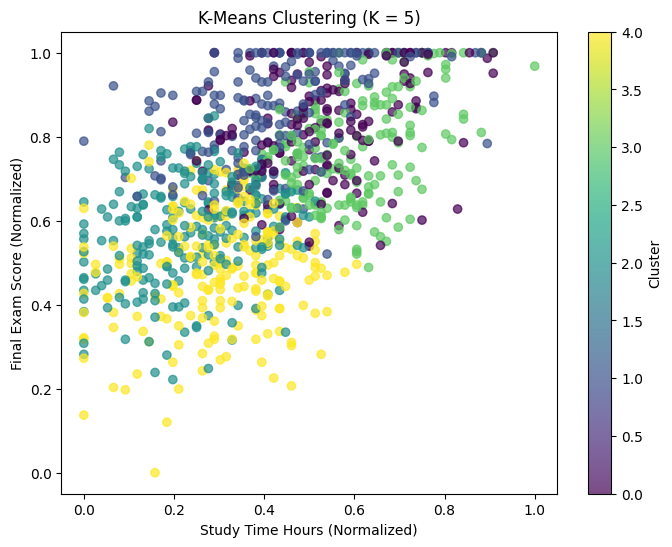

In [24]:

# Visualize clusters for K = 5
plt.figure(figsize=(8, 6))

plt.scatter(
    X_cluster['study_time_hours'],
    X_cluster['final_exam_score'],
    c=cluster_results[5],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('Study Time Hours (Normalized)')
plt.ylabel('Final Exam Score (Normalized)')
plt.title('K-Means Clustering (K = 5)')
plt.colorbar(label='Cluster')
plt.show()


The scatterplots show the clustering assignments in two selected dimensions (`study_time_hours` and `final_exam_score`). The K-Means models were fitted using **five** features, so the two-dimensional plots cannot show separation in all dimensions. Cluster numbers are arbitrary labels and should not be compared as identical groups across different K values.


In [25]:

# Analyze cluster characteristics for K = 3
cluster_data = X_cluster.copy()

cluster_data['Cluster'] = cluster_results[3]

cluster_summary = cluster_data.groupby('Cluster').mean()

print(cluster_summary.round(3))


         study_time_hours  attendance_percent  sleep_hours  previous_grade  \
Cluster                                                                      
0                   0.357               0.869        0.562           0.553   
1                   0.572               0.605        0.539           0.662   
2                   0.296               0.550        0.491           0.475   

         final_exam_score  
Cluster                    
0                   0.734  
1                   0.854  
2                   0.506  


### Cluster Characteristics Analysis

In [26]:

# Analyze cluster characteristics for K = 4 and K = 5
for k in [4, 5]:
    cluster_data = X_cluster.copy()
    cluster_data['Cluster'] = cluster_results[k]

    print(f"\nCluster Characteristics for K = {k}")
    print(cluster_data.groupby('Cluster').mean().round(3))



Cluster Characteristics for K = 4
         study_time_hours  attendance_percent  sleep_hours  previous_grade  \
Cluster                                                                      
0                   0.339               0.851        0.581           0.530   
1                   0.577               0.726        0.532           0.685   
2                   0.227               0.614        0.452           0.493   
3                   0.480               0.445        0.546           0.526   

         final_exam_score  
Cluster                    
0                   0.706  
1                   0.914  
2                   0.462  
3                   0.667  

Cluster Characteristics for K = 5
         study_time_hours  attendance_percent  sleep_hours  previous_grade  \
Cluster                                                                      
0                   0.527               0.854        0.629           0.468   
1                   0.439               0.730        0.516 

### Cluster Interpretation (K = 3)

The K-Means algorithm divided students into three clusters based on five normalized numerical features.

- **Cluster 0:** Students in this cluster have the highest average attendance (0.869) and relatively high final exam scores (0.734). This suggests that attendance may be an important characteristic of this group.
- **Cluster 1:** This cluster has the highest average study time (0.572), previous grade (0.662), and final exam score (0.854). These students demonstrate relatively strong academic performance.
- **Cluster 2:** Students in this cluster have the lowest average study time (0.296), attendance (0.550), previous grade (0.475), and final exam score (0.506). This group shows comparatively lower academic performance.

Overall, the results suggest that study time, attendance, and previous academic performance help distinguish the student groups. However, the clusters overlap, so the results should not be interpreted as evidence of direct cause and effect.

### Cluster Interpretation (K = 4)

K-Means divided the students into four clusters based on their normalized academic and study-related features.

- **Cluster 0:** Students have the highest average attendance (0.851) and relatively good final exam scores (0.706).
- **Cluster 1:** Students have the highest study time (0.577), previous grades (0.685), and final exam scores (0.914), representing the strongest academic performance among the four clusters.
- **Cluster 2:** Students have the lowest study time (0.227) and final exam scores (0.462), indicating comparatively lower academic performance.
- **Cluster 3:** Students have the lowest attendance (0.445), despite moderate study time (0.480) and final exam scores (0.667).

### Cluster Interpretation (K = 5)

K-Means divided the students into five clusters, revealing more detailed differences in study habits and academic performance.

- **Cluster 0:** Students have high attendance (0.854), relatively high study time (0.527), and strong final exam scores (0.824).
- **Cluster 1:** Students have the highest previous grades (0.793) and final exam scores (0.864), indicating strong academic performance.
- **Cluster 2:** Students have relatively high attendance (0.810), but lower study time (0.240) and final exam scores (0.575).
- **Cluster 3:** Students have the highest study time (0.597), with relatively high final exam scores (0.774), despite lower attendance (0.503).
- **Cluster 4:** Students have the lowest attendance (0.463) and final exam scores (0.489), indicating comparatively lower academic performance.

### Comparison of Cluster Characteristics

The three clustering experiments reveal differences in students' study habits, attendance, and academic performance. Increasing K from 3 to 5 produces more detailed student groups, but does not necessarily improve cluster separation. The final selection of K should therefore consider both the evaluation metrics and the interpretability of the resulting clusters.

### Optimal Number of Clusters (K)

The tested values were K = 3, 4, and 5. K = 3 had the highest average Silhouette Score (approximately 0.1771), while K = 5 had the lowest WCSS (approximately 100.5295). Since WCSS generally decreases as K increases, the smallest WCSS is not, by itself, evidence that K = 5 is optimal.

The Elbow plot across only three candidate K values does not show a decisive bend. Therefore, the metrics do **not** establish a majority-rule optimum. We provisionally prefer K = 3 based on its higher Silhouette Score among the three tested values and the interpretability of its cluster profiles. More K values and an additional independent evaluation criterion would be needed to support a stronger majority-rule conclusion.

All Silhouette Scores are low (approximately 0.15–0.18), indicating weak separation. The cluster profiles should be interpreted cautiously.


# 7. Findings and Discussion

### **A. Classification Findings and Discussion**

Decision Tree classification was applied using two splitting criteria: Gini Index and Entropy (Information Gain). Each criterion was evaluated using three different training/testing partitions: 90/10, 80/20, and 70/30.

The results showed that the highest accuracy was achieved by the Gini Index with the 70/30 partition, reaching 45.67%. Entropy achieved its highest accuracy of 44% using the 90/10 partition.

Overall, Gini performed better than Entropy in the 80/20 and 70/30 partitions, while Entropy performed better in the 90/10 partition.

The confusion matrices showed that both models performed better when classifying some categories, particularly A, B, and C, while they experienced difficulties predicting grades D and F. The models also frequently confused grades B and C.

Although Gini achieved the highest accuracy, all six experiments had accuracy values below 50%. This indicates that the Decision Tree models had limited classification performance on this dataset.

These findings suggest that predicting students' final grades using the selected features and Decision Tree models was challenging. Further improvements in feature selection and model development may help improve classification performance.

### 7.1 Final Decision Tree Visualization and Interpretation

The best tested classification model is visualized below. We show only the first three levels (`max_depth=3`) to make the major decision rules readable; **this is a truncated visualization, not the complete tree**. The model itself is unchanged. Each node reports a feature threshold, impurity, sample count, and class distribution.


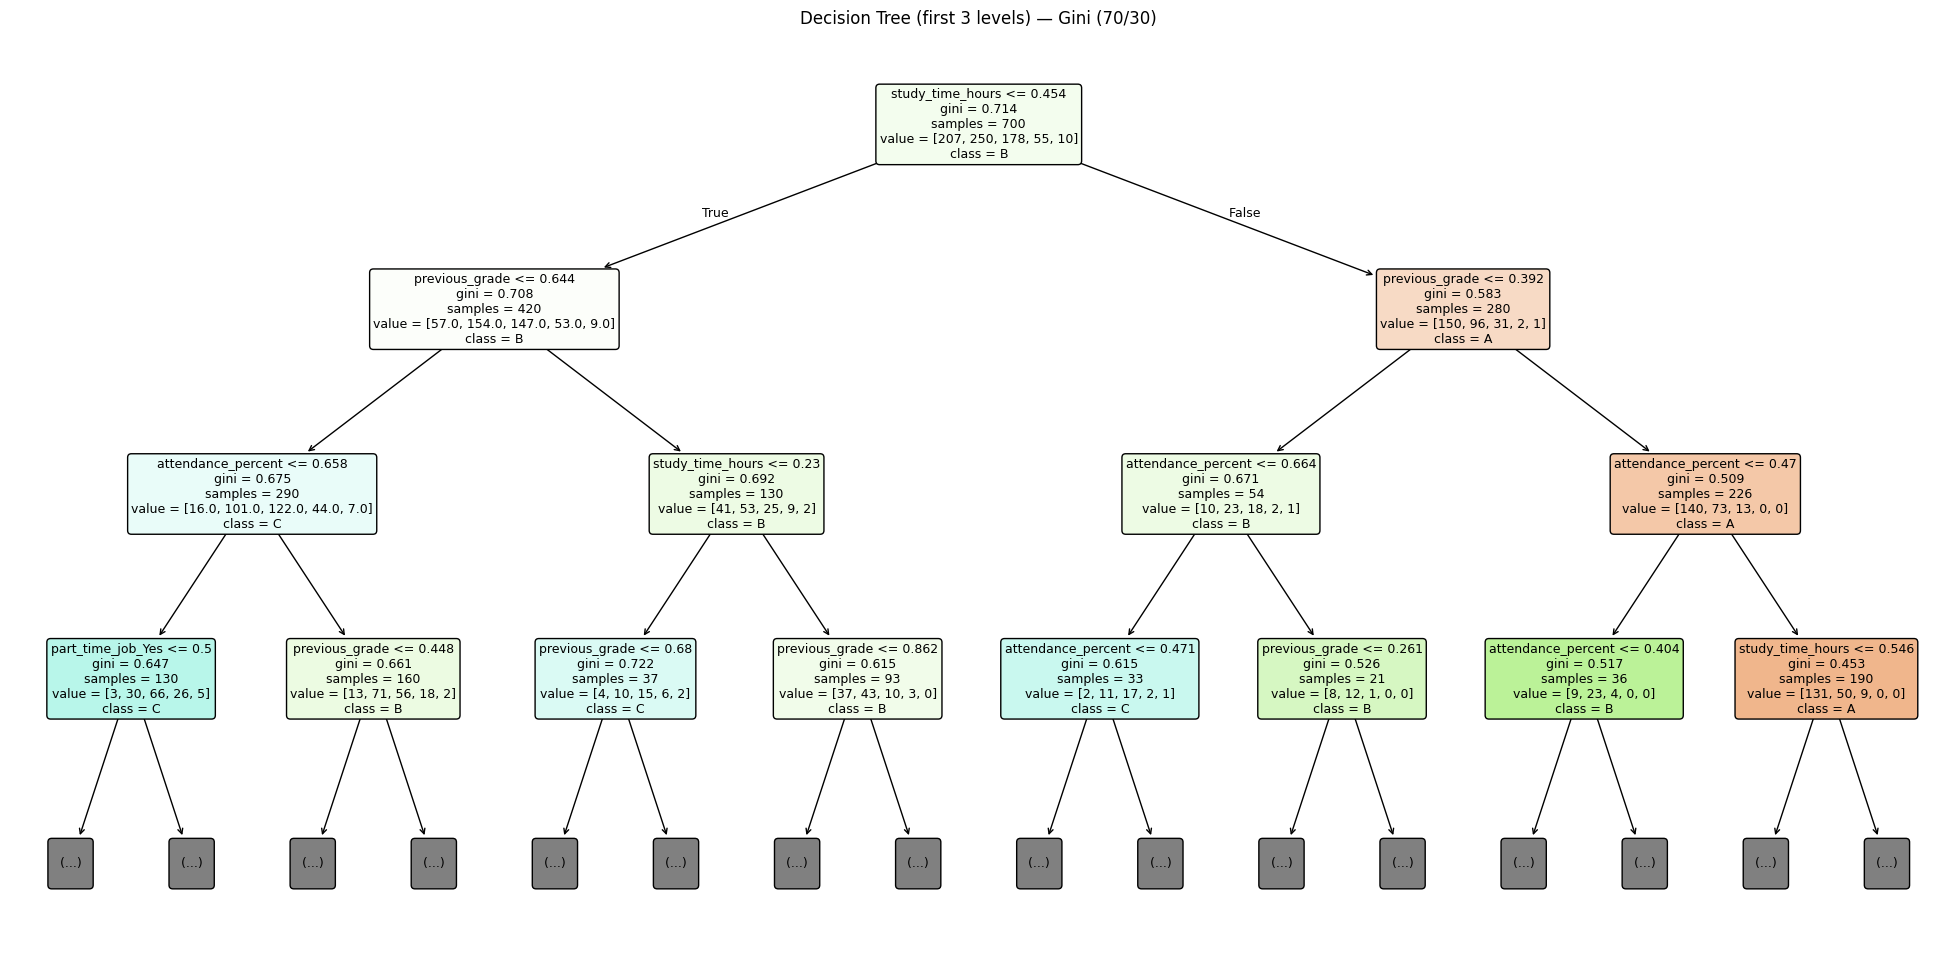

In [27]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Reuse the best model identified in Section 6.1
feature_names = list(best_model.feature_names_in_)
plt.figure(figsize=(25, 12))
plot_tree(best_model, feature_names=feature_names,
          class_names=[str(c) for c in best_model.classes_],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title(f"Decision Tree (first 3 levels) — {best_row['Criterion']} ({best_row['Partition']})")
plt.show()


The Decision Tree visualization shows that study time hours was selected as the root node, indicating its importance in the first split of the data. Previous grade and attendance percentage were also used in subsequent splits to classify students into different grade categories. In addition, part-time job status appeared as one of the splitting features.

The tree demonstrates how the model uses students' study habits and academic information to predict their final grade. However, the classification accuracy was relatively low (45.67%), indicating that the model had difficulty correctly classifying all grade categories.

### 7.2 Best-Model Confusion Matrix: Class-Level Interpretation

In addition to overall accuracy, we examine which grade categories the selected model predicts correctly or confuses with other grades. Rows correspond to actual grades and columns to predicted grades. The diagonal contains correct predictions; off-diagonal cells show errors. Class-specific recall is the proportion of students of each actual grade predicted correctly.


In [28]:
from sklearn.metrics import confusion_matrix, classification_report
_, X_test_best, _, y_test_best = splits[best_row['Test Size']]
y_pred_best = best_model.predict(X_test_best)
cm_best = confusion_matrix(y_test_best, y_pred_best, labels=best_model.classes_)
print('Best-model confusion matrix:')
print(pd.DataFrame(cm_best, index=best_model.classes_, columns=best_model.classes_))
print('\nClass-specific precision, recall and F1:')
print(classification_report(y_test_best, y_pred_best, labels=best_model.classes_, zero_division=0))


Best-model confusion matrix:
    A   B   C  D  F
A  45  25   6  0  1
B  31  51  17  5  0
C  11  28  35  8  1
D   1  10  16  6  1
F   0   0   2  0  0

Class-specific precision, recall and F1:
              precision    recall  f1-score   support

           A       0.51      0.58      0.55        77
           B       0.45      0.49      0.47       104
           C       0.46      0.42      0.44        83
           D       0.32      0.18      0.23        34
           F       0.00      0.00      0.00         2

    accuracy                           0.46       300
   macro avg       0.35      0.33      0.34       300
weighted avg       0.45      0.46      0.45       300



The class-level report provides evidence for the discussion of grades that are difficult to predict. In particular, compare the recall values for A, B, C, D, and F, rather than interpreting the raw diagonal counts alone: classes with different numbers of test students cannot be fairly compared by counts only.


### **B. Clustering Findings and Discussion**


K-Means clustering was applied to the student performance dataset using five normalized numerical features: study time, attendance percentage, sleep hours, previous grade, and final exam score. Three clustering configurations (K = 3, K = 4, and K = 5) were evaluated.

The results showed that K = 3 achieved the highest Silhouette Score (0.1771), compared with 0.1601 for K = 4 and 0.1548 for K = 5. Although WCSS decreased as the number of clusters increased, the Elbow Plot did not show a clearly defined optimal point. Therefore, K = 3 was selected as the preferred configuration based on its relatively better separation and interpretable student groups.

For K = 3, the clustering results revealed three different student profiles:

- **Cluster 0:** Students with the highest average attendance (0.869) and relatively good final exam performance (0.734).
- **Cluster 1:** Students with the highest average study time (0.572), previous grade (0.662), and final exam score (0.854).
- **Cluster 2:** Students with comparatively lower study time (0.296), attendance (0.550), previous grade (0.475), and final exam score (0.506).

The experiments with K = 4 and K = 5 provided more detailed student groupings, but their lower Silhouette Scores indicated that increasing the number of clusters did not improve separation.

Overall, the clustering analysis identified meaningful differences in students' academic performance and study-related characteristics. However, the relatively low Silhouette Scores suggest that the clusters overlap and should be interpreted cautiously. The findings describe associations within the dataset rather than causal relationships.

These results may help identify groups of students with different academic profiles and provide insights for further investigation of student performance.

### **C. Comparison with Previous Research**

The research paper by Khairy et al. (2024), titled *"Prediction of Student Exam Performance Using Data Mining Classification Algorithms,"* investigated the use of data mining techniques to predict students' academic performance [1].

The study used a dataset containing 830 student records and six features. The data was divided into 70% for training and 30% for testing. Five classification algorithms were evaluated: Random Forest, Decision Tree, Naive Bayes, Neural Network, and K-Nearest Neighbors (KNN). The results showed that Random Forest and Decision Tree achieved the highest accuracy of 98.7% [1].

**Comparison with Our Project**

Both studies focus on analyzing students' academic performance using data mining techniques. However, they differ in their datasets, selected features, and experimental settings.

Our project used a dataset containing 1,000 student records and focused on study habits and academic performance. We applied Decision Tree classification using two attribute selection measures, Gini Index and Entropy, with three different training/testing partitions. Our highest classification accuracy was 45.67%, achieved using Gini Index with a 70/30 partition.

Compared with the research paper, our Decision Tree model achieved a lower accuracy. However, this difference does not necessarily mean that our approach is less effective, because the two studies used different datasets, features, and experimental settings. The research paper also evaluated additional classification algorithms, while our project focused on Decision Tree classification.

It is important to note that the selected research paper focused on classification, whereas our project included both classification and K-Means clustering. Therefore, the clustering results cannot be directly compared with the research paper.

Overall, both studies demonstrate how data mining techniques can be used to analyze student academic performance. The comparison also highlights the importance of dataset characteristics, feature selection, and model evaluation when interpreting classification results.

# 8. References

[1] D. Khairy, N. Alharbi, M. A. Amasha, S. Alkhalaf, R. A. Abougalala, and M. F. Areed, "Prediction of student exam performance using data mining classification algorithms," *Education and Information Technologies*, vol. 29, pp. 21621–21645, 2024, doi: 10.1007/s10639-024-12619-w.

[2] harshadapatil31, "Student Performance and Study Habits Dataset," Kaggle. [Online]. Available: https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset